# Models without spatial information

Linear, LSTM and TCN, trained with BasicTS on METR-LA (settings in `src/train/config.py`):
- 12 steps in → 12 out;
- one model shared by all sensors;
- missing values (0) handled as in DCRNN;
- scaler from the training data (mean 54.41, std 19.49); 
- early stopping on validation MAE;
- test set evaluated once at the end, seed 42; 
- LSTM and TCN: 10 epochs only (CPU time).

In [20]:
import torch
from src.model.linear import Linear, LinearConfig
from src.model.lstm import LSTM, LSTMConfig
from src.model.tcn import TCN, TCNConfig

torch.manual_seed(0)
x = torch.randn(2, 12, 207)            # 2 windows, 12 steps, 207 sensors
x2 = x.clone()
x2[:, :, 5] += 10                      # change ONLY sensor 5's input

for name, m in [('Linear', Linear(LinearConfig())), ('LSTM', LSTM(LSTMConfig())), ('TCN', TCN(TCNConfig()))]:
    with torch.no_grad():
        diff = (m(x2) - m(x)).abs().amax(dim=(0, 1))      # biggest change in each sensor's output
    print(f'{name}: output changed for sensors {torch.nonzero(diff > 1e-6).flatten().tolist()}')

Linear: output changed for sensors [5]
LSTM: output changed for sensors [5]
TCN: output changed for sensors [5]


Changing one sensor's input only changes that sensor's forecast: the models use no information from other sensors.

In [21]:
import json
from pathlib import Path

import pandas as pd

rows = []
for path in Path('checkpoints').glob('*/METR-LA_*_12_12/*/test_metrics.json'):
    model, run = path.parts[-4], path.parts[-3]          # e.g. 'LSTM', 'METR-LA_10_12_12'
    m = json.loads(path.read_text())
    for h, minutes in [(3, 15), (6, 30), (12, 60)]:
        r = m[f'horizon_{h}']
        rows.append({'model': model, 'run': run, 'minutes': minutes,
                     'MAE': r['MAE'], 'RMSE': r['RMSE'], 'MAPE %': 100 * r['MAPE']})

table = pd.DataFrame(rows).pivot_table(index=['model', 'run'], columns='minutes',
                                       values=['MAE', 'RMSE', 'MAPE %']).round(2)
table

MAE             MAPE %                RMSE         \
minutes                     15    30    60     15     30     60    15     30   
model  run                                                                     
LSTM   METR-LA_10_12_12   3.27  3.96  5.08   9.14  11.46  15.34  6.40   7.89   
Linear METR-LA_100_12_12  3.81  4.81  6.28   9.37  12.32  17.14  8.17  10.25   
       METR-LA_2_12_12    4.13  5.02  6.67  10.20  12.89  18.17  8.53  10.35   
TCN    METR-LA_10_12_12   3.15  3.85  4.99   8.58  10.96  14.81  6.16   7.73   

                                 
minutes                      60  
model  run                       
LSTM   METR-LA_10_12_12    9.88  
Linear METR-LA_100_12_12  12.37  
       METR-LA_2_12_12    12.62  
TCN    METR-LA_10_12_12    9.79

All three models beat the last-value rule at every horizon. TCN is best (MAE 3.15 / 3.85 / 4.99 at 15 / 30 / 60 min), slightly ahead of LSTM, with 2.6× fewer parameters (6 796 vs 17 932). LSTM and TCN beat both Step 1 rules at 15 and 30 minutes, but at 60 minutes the weekly average is still best (4.19). The linear model has a much higher RMSE (8.17 at 15 min), so it makes some very large errors; one possible cause is missing inputs (0 mph → −2.79 after scaling), which a linear model cannot ignore.

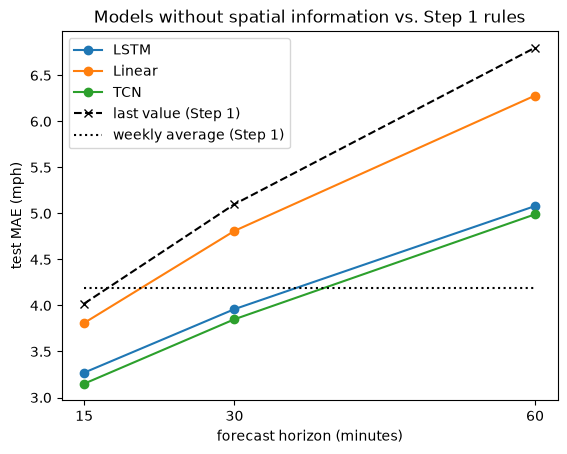

In [22]:
import matplotlib.pyplot as plt

mae = table['MAE']
for (model, run), row in mae.iterrows():
    if run == 'METR-LA_2_12_12':          # skip the 2-epoch test run
        continue
    plt.plot(row.index, row.values, marker='o', label=model)
plt.plot([15, 30, 60], [4.02, 5.10, 6.80], 'k--', marker='x', label='last value (Step 1)')
plt.plot([15, 30, 60], [4.19, 4.19, 4.19], 'k:', label='weekly average (Step 1)')
plt.xticks([15, 30, 60])
plt.xlabel('forecast horizon (minutes)')
plt.ylabel('test MAE (mph)')
plt.title('Models without spatial information vs. Step 1 rules')
plt.legend()
plt.savefig('notebooks/plots/step2_mae_by_horizon.png', dpi=150, bbox_inches='tight')
plt.show()

Linear stopped early after 31 epochs (best at 21) and is fully trained. LSTM and TCN were limited to 10 epochs (about 2 min per epoch on CPU). TCN had flattened out, but LSTM was still improving at epoch 10, so its result is preliminary.

In [23]:
import glob, torch
path = glob.glob('checkpoints/TCN/METR-LA_10_12_12/*/TCN_best_val_MAE.pt')[0]
weights = torch.load(path, map_location='cpu', weights_only=False)['model_state_dict']
weights['blocks.0.conv.weight'][:, 0, :].round(decimals=2)    # 32 rows: [weight on x(t-1), weight on x(t)]

tensor([[ 0.4700,  0.4500],
        [-0.3200,  0.4300],
        [-0.0500,  0.1500],
        [-0.3200,  0.2700],
        [ 0.4700, -0.4900],
        [ 0.4100,  0.1300],
        [ 0.5400,  0.0700],
        [ 0.1800, -0.0100],
        [ 0.4500,  0.0900],
        [-0.3000,  0.1700],
        [-0.2200, -0.0600],
        [-0.2800,  0.4100],
        [-0.3600, -0.1400],
        [-0.1200, -0.2500],
        [ 0.1000, -0.5200],
        [ 0.5300, -0.4400],
        [ 0.3200,  0.1300],
        [-0.0400,  0.2000],
        [ 0.0600,  0.4700],
        [ 0.1200, -0.0800],
        [ 0.1500, -0.1600],
        [ 0.0100,  0.1900],
        [ 0.2800, -0.2500],
        [ 0.0600,  0.0600],
        [ 0.0600, -0.1700],
        [-0.5600, -0.1800],
        [-0.2700,  0.3600],
        [ 0.0800,  0.1700],
        [ 0.1700,  0.0100],
        [ 0.4300, -0.4400],
        [-0.0000, -0.2100],
        [ 0.2000, -0.1700]])

In [24]:
import json
from pathlib import Path

import pandas as pd
import torch

runs = {'speed (12 steps)': Path('checkpoints/TCN/METR-LA_10_12_12')}          # your existing TCN run
runs.update({p.name.removeprefix('TCN_'): p for p in Path('checkpoints/features').glob('TCN_*')})

rows = []
for name, folder in runs.items():
    ckpt = next(folder.glob('*/TCN_best_val_MAE.pt'), None)
    if ckpt is None or not (ckpt.parent / 'test_metrics.json').exists():
        continue                                                 # run not finished yet
    best = torch.load(ckpt, map_location='cpu', weights_only=False)
    test = json.loads((ckpt.parent / 'test_metrics.json').read_text())
    rows.append({'inputs': name, 'best epoch': best['epoch'], 'val MAE': best['best_metrics']['val/MAE'],
                 'test MAE 15': test['horizon_3']['MAE'], 'test MAE 30': test['horizon_6']['MAE'],
                 'test MAE 60': test['horizon_12']['MAE']})
pd.DataFrame(rows).round(3)


,inputs,best epoch,val MAE,test MAE 15,test MAE 30,test MAE 60
0,speed (12 steps),9,3.474,3.150,3.854,4.995
1,speed+tod,7,3.410,3.126,3.766,4.752
2,speed+tod+dow,10,3.344,3.115,3.740,4.651
3,speed_in24,9,3.449,3.142,3.835,4.954
4,speed_in36,10,3.412,3.117,3.803,4.922


Each input was tested on its own on the TCN (10 epochs each) and kept only if the validation MAE dropped.
- Time of day (sine/cosine) lowers the validation MAE from 3.474 to 3.410, and adding day of week lowers it further to 3.344. The gain is largest at 60 minutes (4.99 → 4.65), where the gap to the weekly average shrinks from 0.80 to 0.46 mph.
- A longer input also helps: 24 steps gives 3.449 and 36 steps (3 hours) gives 3.412, about as much as time of day on validation. At 60 minutes, however, the gain is small (4.92, compared with 4.75 for time of day), and training is 3× slower.
- Best so far: speed + time of day + day of week. Not tested yet: 36 steps together with time of day and day of week. The best runs were still improving at epoch 10.

### Finding where the model fails

Load the errors:

In [25]:
import pickle
from pathlib import Path

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd


def load_errors(model, run):
    """Absolute test errors [windows, 12 steps, 207 sensors] in mph, NaN where the target is missing.
    BasicTS writes the results as raw binary despite the .npy name, so np.load fails: use np.fromfile."""
    run_dir = next(Path(f'checkpoints/{model}/{run}').glob('*/'))
    read = lambda name: np.fromfile(run_dir / 'test_results' / name, dtype=np.float32).reshape(-1, 12, 207)
    pred, true = read('prediction.npy'), read('targets.npy')
    return np.where(true != 0, np.abs(pred - true), np.nan)


errors = {'Linear': load_errors('Linear', 'METR-LA_100_12_12'),
          'LSTM': load_errors('LSTM', 'METR-LA_10_12_12'),
          'TCN': load_errors('TCN', 'METR-LA_10_12_12')}


Place the error per sensor on the map:

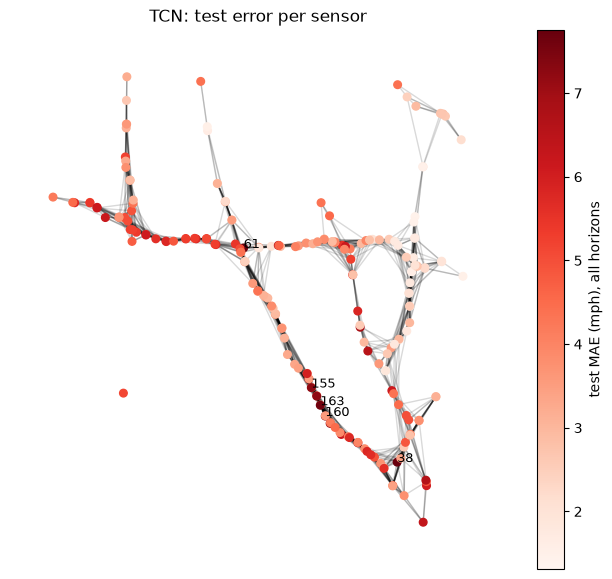

In [26]:
per_sensor = np.nanmean(errors['TCN'], axis=(0, 1))            # one MAE per sensor

loc = pd.read_csv('data/METR-LA/graph_sensor_locations.csv')
with open('data/METR-LA/adj_mx.pkl', 'rb') as f:
    sensor_ids, _, adj = pickle.load(f, encoding='latin1')
A = adj.copy()
np.fill_diagonal(A, 0)
G = nx.from_numpy_array(A > 0, create_using=nx.DiGraph)
pos = {i: (loc.longitude[i], loc.latitude[i]) for i in range(207)}

plt.figure(figsize=(8, 7))
nx.draw_networkx_edges(G, pos, alpha=0.15, arrows=False)
nodes = nx.draw_networkx_nodes(G, pos, nodelist=list(range(207)), node_color=per_sensor, cmap='Reds', node_size=30)
plt.colorbar(nodes, label='test MAE (mph), all horizons')
for i in np.argsort(per_sensor)[-5:]:                          # label the 5 worst sensors
    plt.annotate(str(i), pos[i], fontsize=9)
plt.title('TCN: test error per sensor')
plt.axis('off')
plt.savefig('notebooks/plots/step2_error_map.png', dpi=150, bbox_inches='tight')
plt.show()


Per-sensor test MAE ranges from 1.3 to 7.8 mph (median 3.7). [Describe where the worst sensors are: scattered, or clustered on one stretch of road? Name them.]

### Error by time of day

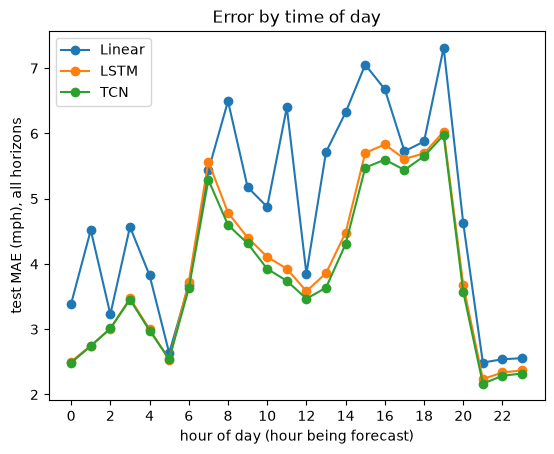

In [27]:
ts = np.load('data/METR-LA/test_timestamps.npy')
W = errors['TCN'].shape[0]
idx = np.arange(W)[:, None] + 12 + np.arange(12)[None, :]     # time step of every target in the test split
hour = (ts[idx, 0] * 24).astype(int)                          # its hour of day, shape [windows, 12]

for name, err in errors.items():
    plt.plot(range(24), [np.nanmean(err[hour == h]) for h in range(24)], marker='o', label=name)
plt.xticks(range(0, 24, 2))
plt.xlabel('hour of day (hour being forecast)')
plt.ylabel('test MAE (mph), all horizons')
plt.title('Error by time of day')
plt.legend()
plt.savefig('notebooks/plots/step2_error_by_hour.png', dpi=150, bbox_inches='tight')
plt.show()

Errors are grouped by the hour of the value being predicted, not the hour when the forecast was made: a 60-minute forecast made at 16:00 counts under 17:00.

Errors are lowest at night and highest in the rush hours, about twice as large around 17:00–19:00 as at night. Errors are larger when traffic changes quickly.

60 minute forecasts compared to weekly average:

weekly average MAE (60-min targets): 4.19


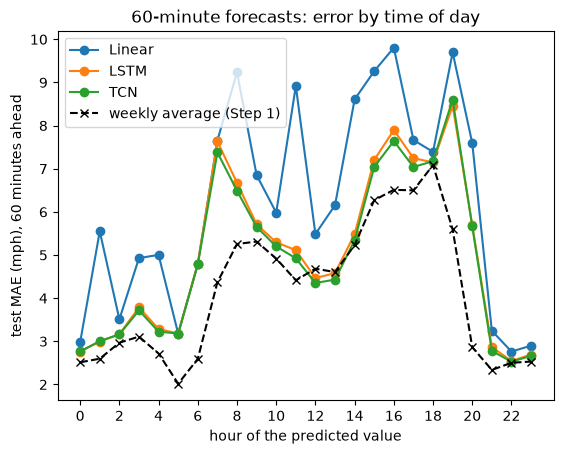

In [28]:
def week_slot(t):
    """Timestamps [..., 2] -> slot 0..2015 of the week (day of week * 288 + 5-min step of the day)."""
    return (np.round(t[..., 1] * 7).astype(int) % 7) * 288 + np.round(t[..., 0] * 288).astype(int) % 288

# weekly-average rule from Step 1: mean speed per (day of week, time of day) slot, from the training data
train = np.load('data/METR-LA/train_data.npy')
train_slot = week_slot(np.load('data/METR-LA/train_timestamps.npy'))
train = np.where(train == 0, np.nan, train)                            # skip missing values in the average
week = np.stack([np.nanmean(train[train_slot == s], axis=0) for s in range(2016)])   # [2016 slots, 207]

# its errors on the same 60-minute targets as the models
test = np.load('data/METR-LA/test_data.npy')
t60 = idx[:, 11]                                                       # time step of each 60-min target
true60 = test[t60]                                                     # [windows, 207]
err_week = np.where(true60 != 0, np.abs(week[week_slot(ts[t60])] - true60), np.nan)
print('weekly average MAE (60-min targets): %.2f' % np.nanmean(err_week))   # should be 4.19, as in Step 1

hour60 = hour[:, 11]                                                   # hour of each 60-min target
for name, err in errors.items():
    plt.plot(range(24), [np.nanmean(err[:, 11][hour60 == h]) for h in range(24)], marker='o', label=name)
plt.plot(range(24), [np.nanmean(err_week[hour60 == h]) for h in range(24)], 'k--', marker='x', label='weekly average (Step 1)')
plt.xticks(range(0, 24, 2))
plt.xlabel('hour of the predicted value')
plt.ylabel('test MAE (mph), 60 minutes ahead')
plt.title('60-minute forecasts: error by time of day')
plt.legend()
plt.savefig('notebooks/plots/step2_error_by_hour_60min.png', dpi=150, bbox_inches='tight')
plt.show()


One hour ahead, the weekly average beats all models for most of the day, especially at the start of the morning rush (06–08) and the end of the evening rush (19–20): from the last hour alone, a model cannot know that a rush is about to start or end. Around midday the models are as good as the weekly average.